# Import and fit a Carterra single-cycle titration

Import **`carterra_rows.csv`**, inspect its metadata, and plot the measured
sensorgrams. This example uses a full-resolution selection committed with the repository;
it uses pyKinGenie's one-site fitter and compares its output with the author report. No data download is required.

**Data origin:** [Duke TitrationAnalysis Carterra workbook](https://github.com/DukeCHSI/TitrationAnalysis/tree/cb8112503658d24c4c6576503243fa506bf99e27/Example%20Files%20-%20Carterra). TitrationAnalysis tool, Kan Li and S Moses Dennison, Duke University. [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).
This is a modified excerpt/conversion; the exact changes and pinned sources
are listed in [SOURCES.md](data/spr_exports/SOURCES.md).
The data and plotted sensorgrams retain their upstream license:
[full license notice](../test_files/spr_exports/TitrationAnalysis-LICENSE).

**Timing limitation:** the 1140 s cycle period is reconstructed from nominal protocol durations. An absolute injection log was not available. The fitted kinetic constants are conditional on this assumption; the notebook is not an exact reproduction of the published analysis.

In [1]:
from pathlib import Path
import sys
import warnings
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

%matplotlib inline

# Works from the repository root, notebooks/, or docs/notebooks/.
cwd = Path.cwd().resolve()
repo_root = next(
    path for path in (cwd, *cwd.parents)
    if (path / "src" / "pykingenie").is_dir()
    and (path / "test_files" / "spr_exports").is_dir()
)
for path in [repo_root / "src"]:
    sys.path.insert(0, str(path))
from pykingenie import detect_file_format, CarterraExperiment, KineticsAnalyzer, plot_plate_info

plt.rcParams.update({"figure.dpi": 110, "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
data_file = repo_root / "notebooks" / "data" / "spr_exports" / "carterra_rows.csv"
print("Input:", data_file.name)
fit_metadata = json.loads((data_file.parent / "fit_metadata.json").read_text())[data_file.stem]

Input: carterra_rows.csv


## File layout and single-cycle import

The CSV retains **all 13 injections** for one physical sensor (Block 1/A1/ROI 1),
worksheet rows 2–14, in their original acquisition order. The five concentrations
on page 1 of the author fit report are injections **9–13** (worksheet rows 10–14):
**62.5, 125, 250, 500, 1000 nM**. Earlier injections are retained for the initial
alignment and chronological context; the comparison fit still selects five.

Use `single_cycle=True, cycle_duration=1140` to combine the row-wise exports into
one sensor with **27 steps**: baseline, association, dissociation, association,
dissociation, ... . Each following pre-association baseline extends the preceding
dissociation because analyte is absent during that interval. Responses are not
shifted or interpolated during import, and source labels are retained in
`ligand_conc_df["Source_curve"]`.

**Clock assumption:** 1140 s is the nominal sum of the source sheet's baseline
120 s, association 300 s and fitted dissociation 720 s. This is an explicit
protocol-based reconstruction, not a recovered absolute injection log. Use the
actual cycle period when available. The source excerpts retain all finite points
in each row's 0–1140 s window; their later export tails are omitted and recorded
in the manifest. No response is smoothed or replaced.

In [2]:
association_start = fit_metadata["association_start"]
association_end = fit_metadata["association_end"]

print("Detected layout:", detect_file_format(data_file))

experiment = CarterraExperiment("carterra_rows")
with warnings.catch_warnings(record=True) as messages:
    warnings.simplefilter("always", UserWarning)
    experiment.read_csv(
        data_file,
        association_start=association_start,
        association_end=association_end,
        decimal='.',
        time_unit="s",
        sample_id=fit_metadata["analyte"],
        concentrations=fit_metadata["cycle_concentrations"],
        concentration_unit="uM",
        single_cycle=True,
        cycle_duration=fit_metadata["cycle_duration_seconds"],
    )
for message in messages:
    print(message.message)
print(f"Imported {experiment.no_sensors} sensor, {len(experiment.ligand_conc_df)} injections; {experiment.no_steps} API phases.")
assert experiment.traces_loaded and experiment.no_sensors == 1
assert experiment.no_steps == 27
assert experiment.exp_info["single_cycle"]
assert len(experiment.ligand_conc_df) == 13

Detected layout: carterra_csv
Imported 1 sensor, 13 injections; 27 API phases.


## Available curve information

All 13 row-wise curves belong to one physical sensor in this single-cycle import.
Original labels remain in `ligand_conc_df["Source_curve"]`. The table below extracts
fields present in those labels and identifies the five published concentrations
selected for fitting.

In [3]:
curve_ids = [f"Injection {i + 1}" for i in range(len(experiment.ligand_conc_df))]
labels = experiment.ligand_conc_df["Source_curve"].rename("Exported label")
header_info = labels.str.extract(
    r"^\[Ligand (?P<Ligand_index>\d+)-(?P<Ligand_label>\S+)\s+"
    r"(?P<Concentration_label>[^\]]+)\]\s+\[(?P<Fit_status>[^\]]+)\]$"
)
header_info.insert(0, "Injection", curve_ids)
header_info["Used in published comparison"] = experiment.ligand_conc_df["Analyte_location"].astype(int).isin(
    fit_metadata["source_concentration_entries_one_based"]
)
display(header_info)
display(labels.to_frame())

,Injection,Ligand_index,Ligand_label,Concentration_label,Fit_status,Used in published comparison
0,Injection 1,1,AE.A244,Conc. 13,NotFitted,False
1,Injection 2,1,AE.A244,Conc. 12,NotFitted,False
2,Injection 3,1,AE.A244,Conc. 11,NotFitted,False
3,Injection 4,1,AE.A244,Conc. 10,NotFitted,False
4,Injection 5,1,AE.A244,Conc. 9,NotFitted,False
5,Injection 6,1,AE.A244,Conc. 8,NotFitted,False
6,Injection 7,1,AE.A244,Conc. 7,NotFitted,False
7,Injection 8,1,AE.A244,Conc. 6,NotFitted,False
8,Injection 9,1,AE.A244,Conc. 5,NotFitted,True
9,Injection 10,1,AE.A244,Conc. 4,NotFitted,True


,Exported label
0,[Ligand 1-AE.A244 Conc. 13] [NotFitted]
1,[Ligand 1-AE.A244 Conc. 12] [NotFitted]
2,[Ligand 1-AE.A244 Conc. 11] [NotFitted]
3,[Ligand 1-AE.A244 Conc. 10] [NotFitted]
4,[Ligand 1-AE.A244 Conc. 9] [NotFitted]
5,[Ligand 1-AE.A244 Conc. 8] [NotFitted]
6,[Ligand 1-AE.A244 Conc. 7] [NotFitted]
7,[Ligand 1-AE.A244 Conc. 6] [NotFitted]
8,[Ligand 1-AE.A244 Conc. 5] [NotFitted]
9,[Ligand 1-AE.A244 Conc. 4] [NotFitted]


## Verified concentration metadata

The original companion sample sheet supplies **molar concentrations**, independent
of the ambiguous export labels. The explicit mapping in `fit_metadata.json`
converts the author's values from M to µM. These concentrations are passed to the
reader; no molecular weight or interpretation of a truncated unit is guessed.
The fit section below displays the source and mapping.

In [4]:
concentration_info = experiment.ligand_conc_df.copy()
concentration_info.insert(0, "Injection", curve_ids)
display(concentration_info[["Injection", "Concentration_micromolar", "SampleID"]])
assert concentration_info["Concentration_micromolar"].notna().all()

,Injection,Concentration_micromolar,SampleID
0,Injection 1,0.000244,AE.A244
1,Injection 2,0.000488,AE.A244
2,Injection 3,0.000977,AE.A244
3,Injection 4,0.001950,AE.A244
4,Injection 5,0.003910,AE.A244
5,Injection 6,0.007810,AE.A244
6,Injection 7,0.015600,AE.A244
7,Injection 8,0.031300,AE.A244
8,Injection 9,0.062500,AE.A244
9,Injection 10,0.125000,AE.A244


## Plate information, when available

The ligand and concentration indices are not verified chip spots or plate wells. The retained rows contain no row/column mapping, so no plate layout can be drawn.

The conditional cell below uses `plot_plate_info` only when the experiment
actually contains the required plate metadata. It prints a message for this
file rather than assigning artificial well positions.

In [5]:
analyzer = KineticsAnalyzer()
analyzer.add_experiment(experiment, experiment.name)
plate_fields = (
    "sample_row", "sample_column", "sample_type", "sample_id", "sample_conc_labeled"
)
have_plate_info = all(
    getattr(experiment, field) is not None
    and len(getattr(experiment, field)) > 0
    for field in plate_fields
)
if have_plate_info:
    display(pd.DataFrame({field: getattr(experiment, field) for field in plate_fields}))
    plot_plate_info(analyzer, experiment.name).show()
else:
    print("No plate-well coordinates are available in this export; no plate plot is created.")

No plate-well coordinates are available in this export; no plate plot is created.


## Imported single-cycle sensorgram

Plot every retained observation on the reconstructed common clock, before
alignment. The signal already bound remains visible as concentration increases.
Vertical lines mark associations; no independent zeroing is applied to later
injections.

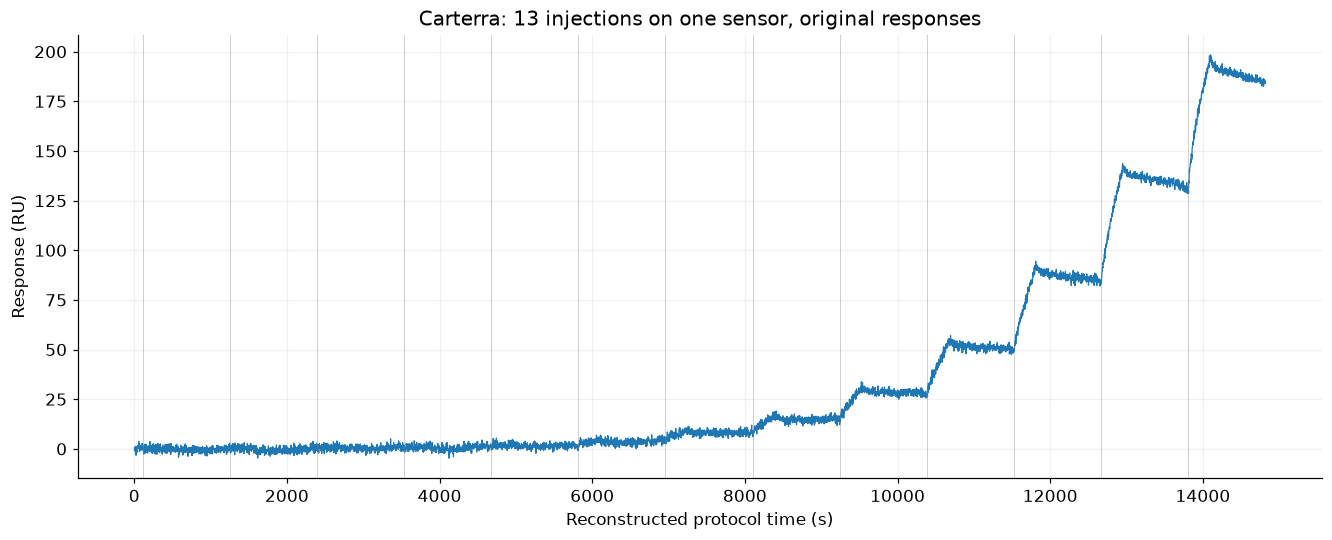

In [6]:
time = np.concatenate(experiment.xs[0])
response = np.concatenate(experiment.ys[0])
fig, ax = plt.subplots(figsize=(12, 4.8), constrained_layout=True)
ax.plot(time, response, linewidth=0.8)
for start in experiment.df_steps.loc[experiment.df_steps["Type"] == "ASSOC", "Start"]:
    ax.axvline(start, color="grey", linewidth=0.6, alpha=0.4)
ax.set(xlabel="Reconstructed protocol time (s)", ylabel="Response (RU)",
       title="Carterra: 13 injections on one sensor, original responses")
ax.grid(alpha=0.18)
plt.show()

## Check the imported sequence

There is one sensor and 13 association/dissociation pairs. Each injection has its
own concentration/location in `ligand_conc_df`. Later baseline observations
belong to the preceding dissociation; they are not new empty-surface baselines.

In [7]:
display(experiment.df_steps[["Name", "Type", "Start"]])
print("Retained observations:", sum(len(step) for step in experiment.xs[0]))
assert np.all(np.diff(np.concatenate(experiment.xs[0])) > 0)

,Name,Type,Start
0,Baseline,BASELINE,1.25
1,Association 1,ASSOC,120.00
2,Dissociation 1,DISASSOC,420.00
3,Association 2,ASSOC,1260.00
4,Dissociation 2,DISASSOC,1560.00
5,Association 3,ASSOC,2400.00
6,Dissociation 3,DISASSOC,2700.00
7,Association 4,ASSOC,3540.00
8,Dissociation 4,DISASSOC,3840.00
9,Association 5,ASSOC,4680.00


Retained observations: 6717


The fitting copy below retains this complete sequence. Only the five published concentrations are selected for parameter estimation.

## Published one-site model

The original Carterra sample sheet specifies association **120–420 s**,
dissociation **420–1140 s**, no regeneration and no bulk shift. Fit a **one-site
Langmuir single-cycle model with local Smax using pyKinGenie**, comparing
with Block 1 / A1 / ROI 1, fitting #1 in the author report. Selected worksheet
rows **10–14** map to **0.0625, 0.125, 0.25, 0.5, 1.0 µM** by source row
order, matching page 1 of the author sensorgram report.

The importer now preserves a common clock and emits alternating `ASSOC` /
`DISASSOC` steps. `align_association` aligns only the first baseline; the existing
method skips later associations immediately following a dissociation. The
selected first injection already has bound material: the existing fitter
estimates its starting signal from that association. Subsequent injections
carry their bound signal from the preceding fitted dissociation. No custom
fitting function or per-injection reset is used.

Reference: [Li et al., TitrationAnalysis](https://pmc.ncbi.nlm.nih.gov/articles/PMC10667272/) and the [author report](https://github.com/DukeCHSI/TitrationAnalysis/blob/cb8112503658d24c4c6576503243fa506bf99e27/Example%20Files%20-%20Carterra/Titration%20Analysis_Carterra_Report_Example.csv). The original CSV is included locally with provenance in [SOURCES.md](data/spr_exports/SOURCES.md).

This notebook fits the **same five concentration curves** as the author report,
within the same nominal protocol windows. No alternative models or model selection are run.

## Align once and use pyKinGenie's single-cycle fitter

Call the existing `align_association(inplace=True, npoints=10)` on a copy of
the full imported sequence. All later associations follow `DISASSOC`, so the
method leaves their relative starting responses intact.

Generate the fit using the five author-selected injections with `trim_time=0`.
The preceding baseline before each subsequent association remains part of the
zero-analyte dissociation and is fitted as such. Thus the continuous fit includes
these inter-injection wash observations in addition to the author's nominal
per-row dissociation window. The global clock is reconstructed from the explicit
cycle period above; no original absolute timing log was available.

The existing fitter, not notebook code, handles the initial signal and bound-state
carry-over. No alternative models or optimizers are introduced.

In [8]:
from copy import deepcopy
from pykingenie.utils.processing import detect_time_list_continuos

fit_experiment = deepcopy(experiment)
fit_experiment.align_association(inplace=True, npoints=10)

fit_analyzer = KineticsAnalyzer()
fit_analyzer.add_experiment(fit_experiment, fit_experiment.name)
fit_analyzer.merge_ligand_conc_df()
selected = fit_analyzer.combined_ligand_conc_df.copy()
selected["Select"] = selected["Analyte_location"].astype(int).isin(
    fit_metadata["source_concentration_entries_one_based"]
)
assert selected["Select"].sum() == 5
np.testing.assert_allclose(
    selected.loc[selected["Select"], "[Analyte] (μM)"], fit_metadata["concentrations"]
)
messages = fit_analyzer.generate_fittings(selected, trim_time=0)
print("\n".join(messages))
fit_analyzer.submit_steady_state_fitting()

Creating a new fitting object for sample: AE.A244


In [9]:
fitter = next(iter(fit_analyzer.fittings.values()))
assert fitter.is_single_cycle
continuity = detect_time_list_continuos(fitter.time_assoc_lst, fitter.time_disso_lst)
assert all(continuity[1:])
print("Single-cycle fitter:", fitter.is_single_cycle)
print("Carry state from previous dissociation:", continuity)
fitter.fit_one_site_assoc_and_disso(shared_smax=False, calc_loo=False)
display(fitter.fit_params_kinetics)

Single-cycle fitter: True
Carry state from previous dissociation: [np.False_, np.True_, np.True_, np.True_, np.True_]


,Concentration [µM],Kd [µM],k_off [1/s],Smax,(Derived) k_on [1/µM/s]
0,0.0625,0.016424,0.000077,225.232448,0.004679
1,0.1250,0.016424,0.000077,188.911912,0.004679
2,0.2500,0.016424,0.000077,189.647429,0.004679
3,0.5000,0.016424,0.000077,198.084702,0.004679
4,1.0000,0.016424,0.000077,216.573531,0.004679


## Single-cycle one-site fit from pyKinGenie

The package's `plot_association_dissociation` displays observations and the
fitted curves returned by `KineticsFitter`. Its plotting budget limits displayed
points only; the fit uses all observations allowed by `trim_time`.

**Check the published figure:** [Author fitted-sensorgram PDF](https://github.com/DukeCHSI/TitrationAnalysis/blob/cb8112503658d24c4c6576503243fa506bf99e27/Example%20Files%20-%20Carterra/Titration%20Analysis_Carterra_Sensorgram_Example.pdf).
Locate Block 1 / A1 / ROI 1, fitting #1; ligand CH31 10 µg/ml, analyte AE.A244. The same five concentrations are shown on **page 1** of that report.

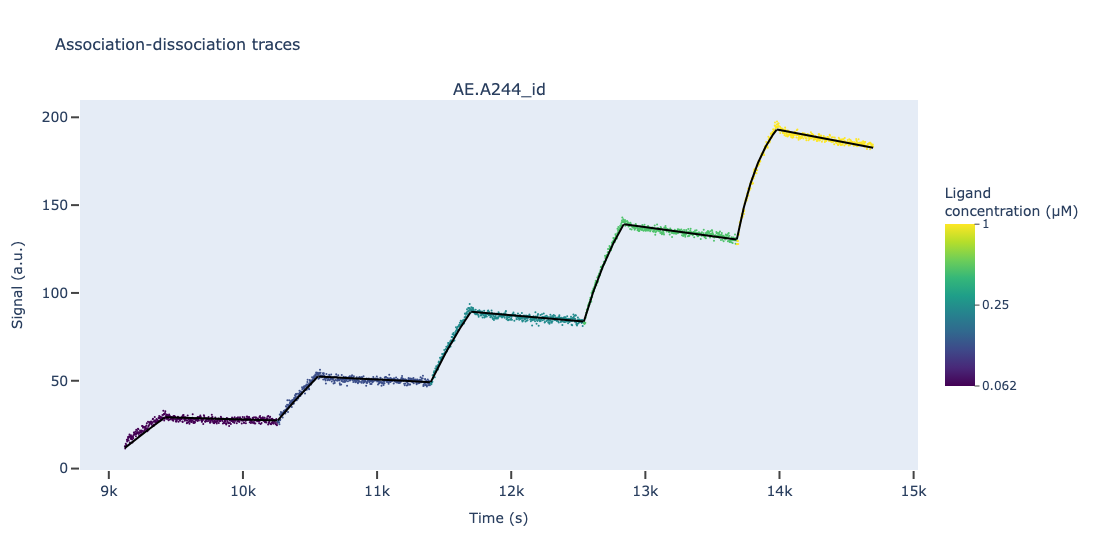

In [10]:
from pykingenie import plot_association_dissociation
from IPython.display import Image

fig_fit = plot_association_dissociation(
    fit_analyzer, split_by_smax_id=False,
    plot_width=22, plot_height=11, marker_size=2, line_width=2,
)
display(Image(data=fig_fit.to_image(format="png", width=1100, height=550)))

## Compare pyKinGenie's fitted parameters with the published values

The table uses `fitter.Kd` and `fitter.k_off` directly. kon is their ratio.
Only unit conversion and percentage differences are calculated below.
Local Smax values are shown in the library result table above.

**Check the published numbers:** [Original parameter table (PDF)](https://github.com/DukeCHSI/TitrationAnalysis/blob/cb8112503658d24c4c6576503243fa506bf99e27/Example%20Files%20-%20Carterra/Titration%20Analysis_Carterra_Report_Example.pdf) or [machine-readable values (CSV)](https://github.com/DukeCHSI/TitrationAnalysis/blob/cb8112503658d24c4c6576503243fa506bf99e27/Example%20Files%20-%20Carterra/Titration%20Analysis_Carterra_Report_Example.csv).
Use Block 1 / A1 / ROI 1, fitting #1; ligand CH31 10 µg/ml, analyte AE.A244. These are the values in the Published column below.

In [11]:
reference = fit_metadata["literature_reference"]["parameters_molar"]
comparison = pd.DataFrame({
    "Parameter": ["kon", "koff", "Kd"],
    "Unit": ["M⁻¹ s⁻¹", "s⁻¹", "nM"],
    "Published": [reference["kon"], reference["koff"], reference["Kd"] * 1e9],
    "pyKinGenie": [fitter.k_off / fitter.Kd * 1e6, fitter.k_off, fitter.Kd * 1e3],
})
comparison["Difference (%)"] = 100 * (comparison["pyKinGenie"] / comparison["Published"] - 1)
display(comparison.style.format({
    "Published": "{:.5g}", "pyKinGenie": "{:.5g}", "Difference (%)": "{:+.2f}",
}))

,Parameter,Unit,Published,pyKinGenie,Difference (%)
0,kon,M⁻¹ s⁻¹,5161.2,4679.3,-9.34
1,koff,s⁻¹,7.3734e-05,7.6854e-05,+4.23
2,Kd,nM,14.286,16.424,+14.97


## Scope of the comparison

The five author-selected concentrations are fitted using the existing
pyKinGenie single-cycle path. The response is no longer reset separately for
each injection. All subsequent selected associations carry state from a fitted
dissociation, including the intervening baseline wash.

The published and notebook fits still differ in initial-state estimation,
wash-window inclusion, sampling and fitting details. The reconstructed cycle
period is based on the source sheet, not an absolute acquisition log. The
comparison table reports the actual native-library results; it is not an exact
reproduction or validation of intrinsic kinetic constants.

See [SPR_FITTING.md](SPR_FITTING.md) for API calls and reference reports.